# Non-AI counting (OpenCV)

Walk-through of `count.py`: foreground segmentation, counting, masks and evaluation.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

from count import count_image, foreground, load, overlay

DATA = Path("../../../data")  # unzipped dataset (not stored in git)
plt.rcParams["figure.dpi"] = 60


def show(images, titles, size=6):
    """Show images side by side, downscaled to keep the notebook small."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size), squeeze=False)
    for ax, img, title in zip(axes[0], images, titles, strict=True):
        small = cv2.resize(img, None, fx=0.4, fy=0.4, interpolation=cv2.INTER_AREA)
        ax.imshow(small if small.ndim == 2 else cv2.cvtColor(small, cv2.COLOR_BGR2RGB), cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Foreground

A polynomial background fit removes shading and lens vignetting; Otsu thresholds the difference.

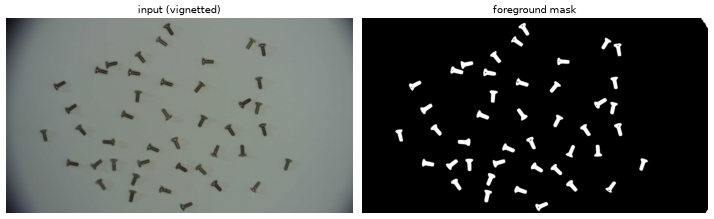

In [2]:
img = load(DATA / "Screws_2024_07_15/img4.jpg")
show([img, foreground(img)], ["input (vignetted)", "foreground mask"])

## 2. Counting and masks

* **Nuts:** one nut per hole, pixels assigned to the nearest hole.
* **Screws:** round objects found as distance-transform peaks; touching groups divided by the area of one screw.

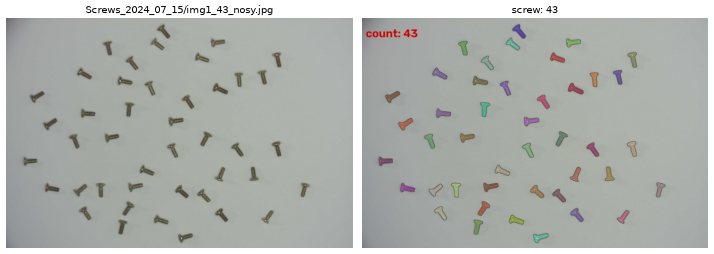

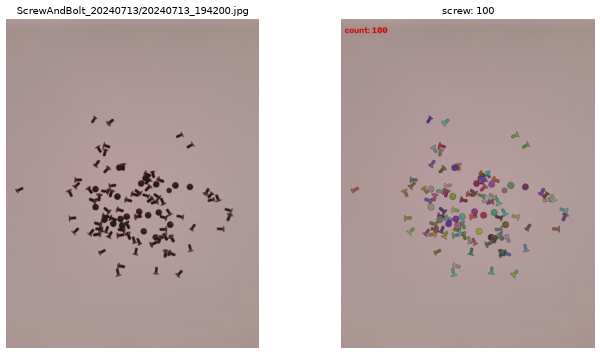

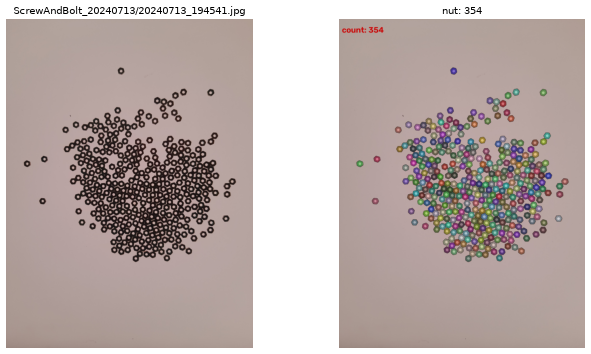

In [3]:
for name in [
    "Screws_2024_07_15/img1_43_nosy.jpg",
    "ScrewAndBolt_20240713/20240713_194200.jpg",
    "ScrewAndBolt_20240713/20240713_194541.jpg",
]:
    res = count_image(DATA / name)
    show([res.image, overlay(res)], [name, f"{res.kind}: {res.count}"])

## 3. Accuracy against `../ground_truth.json`

In [4]:
!uv run evaluate.py {DATA} -o outputs

image                                       true  pred     acc  match  merge  miss   fp


ScrewAndBolt_20240713/20240713_192951.jpg     21    21 100.00%     21      0     0    0


ScrewAndBolt_20240713/20240713_193135.jpg     21    21 100.00%     21      0     0    0


ScrewAndBolt_20240713/20240713_193650.jpg     10    10 100.00%     10      0     0    0


ScrewAndBolt_20240713/20240713_193659.jpg     10    10 100.00%     10      0     0    0


ScrewAndBolt_20240713/20240713_193831.jpg    193   197  97.93%    191      2     0    6


... (16 outputs left out)

Screws_2024_07_15/img3.jpg                    43    43 100.00%     43      0     0    0


Screws_2024_07_15/img4.jpg                    43    43 100.00%     43      0     0    0


Screws_2024_07_15/img5.jpg                    43    43 100.00%     43      0     0    0


Screws_2024_07_15/img6.jpg                    43    43 100.00%     43      0     0    0

ALL: mean per-image accuracy 99.60% (min 97.93%), total true 3307 predicted 3318 -> 99.67%
